# Finals #09 Part 2 — do the app's form rules match real makes?

Question: do shots the app's `evaluate_form` calls "good" on a checkpoint actually go in more than shots it calls "needs_work"? And do shots with a higher overall form score go in more often?

In [1]:
import sys
sys.path.insert(0, "..")
import pandas as pd, numpy as np
from ml.feedback_rules import evaluate_form

df = pd.read_csv("../data/features.csv")
print(len(df), "shots,", df.made.mean().round(2), "made rate,", df.player.nunique(), "players")
print(df.player.value_counts().to_dict())

89 shots, 0.53 made rate, 11 players
{'Ryan': 14, 'Abby': 11, 'Freya': 9, 'Kelvin_Huang': 9, 'Manoj': 9, 'Veronica': 9, 'Anisha': 8, 'Aaron': 8, 'Audrey': 6, 'David': 4, 'Rijul': 2}


In [2]:
def evaluate(row):
    r = evaluate_form({"elbow_angle": row.elbow_at_release, "knee_angle": row.knee_at_release,
                        "shoulder_angle": row.shoulder_at_release})
    out = {f["checkpoint"]: f["status"] for f in r["feedback"]}
    out["score"] = r["overall_score"]
    return pd.Series(out)

df = df.join(df.apply(evaluate, axis=1))
for cp in ["elbow_alignment", "knee_bend", "shoulder_position"]:
    print(cp, df.groupby(cp).made.agg(["mean", "count"]).round(2).to_dict())

elbow_alignment {'mean': {'good': 0.6, 'needs_work': 0.42}, 'count': {'good': 53, 'needs_work': 36}}
knee_bend {'mean': {'good': 0.61, 'needs_work': 0.39}, 'count': {'good': 56, 'needs_work': 33}}
shoulder_position {'mean': {'good': 0.56, 'needs_work': 0.39}, 'count': {'good': 71, 'needs_work': 18}}


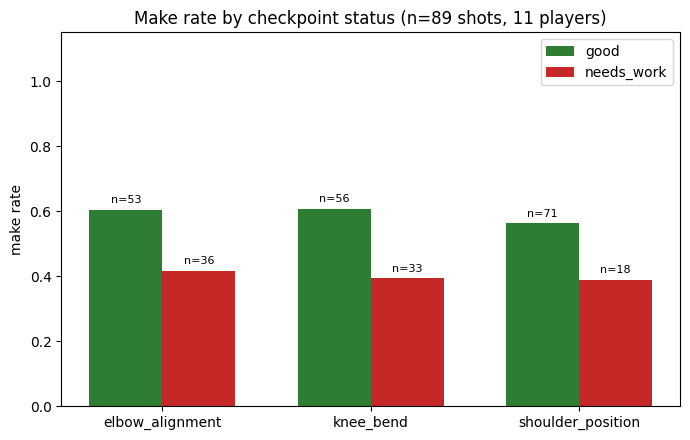

In [3]:
import matplotlib.pyplot as plt

checkpoints = ["elbow_alignment", "knee_bend", "shoulder_position"]
rates, counts = [], []
for cp in checkpoints:
    g = df.groupby(cp).made.agg(["mean", "count"])
    rates.append([g["mean"].get("good", float("nan")), g["mean"].get("needs_work", float("nan"))])
    counts.append([g["count"].get("good", 0), g["count"].get("needs_work", 0)])

fig, ax = plt.subplots(figsize=(7, 4.5))
x = range(len(checkpoints))
width = 0.35
good_rates = [r[0] for r in rates]
needs_work_rates = [r[1] for r in rates]
ax.bar([i - width/2 for i in x], good_rates, width, label="good", color="#2e7d32")
ax.bar([i + width/2 for i in x], needs_work_rates, width, label="needs_work", color="#c62828")
for i, (g, n) in enumerate(zip(good_rates, needs_work_rates)):
    ax.text(i - width/2, g + 0.02, f"n={counts[i][0]}", ha="center", fontsize=8)
    ax.text(i + width/2, n + 0.02, f"n={counts[i][1]}", ha="center", fontsize=8)
ax.set_xticks(list(x)); ax.set_xticklabels(checkpoints)
ax.set_ylabel("make rate"); ax.set_ylim(0, 1.15)
ax.set_title(f"Make rate by checkpoint status (n={len(df)} shots, {df.player.nunique()} players)")
ax.legend()
plt.tight_layout()
plt.savefig("../docs/writeups/img/experiments_a_checkpoint_make_rate.png", dpi=150)
plt.show()

In [4]:
def permutation_p(a, b, n=10_000, seed=0):
    rng = np.random.default_rng(seed)
    observed, pooled = a.mean() - b.mean(), np.concatenate([a, b])
    hits = 0
    for _ in range(n):
        rng.shuffle(pooled)
        hits += abs(pooled[:len(a)].mean() - pooled[len(a):].mean()) >= abs(observed)
    return observed, hits / n

diff, p = permutation_p(df[df.made == 1].score.values, df[df.made == 0].score.values)
print(f"made shots score {diff:.1f} points higher, p = {p:.3f}")
print("made count:", (df.made==1).sum(), "missed count:", (df.made==0).sum())

made shots score 6.6 points higher, p = 0.289
made count: 47 missed count: 42


## Notes on this sample

This now uses the full 89-shot labeled dataset (185 clips were hand-marked; 96 were skipped because MediaPipe did not detect a pose at the release frame, matching Veronica Ting'''s own skip count from her original labeling pass almost exactly). Every one of the 11 players has a mix of makes and misses, so the player/outcome confound from the earlier 21-shot partial run is resolved and this result reflects form, not who shot it.

Sample sizes are still uneven across players (2 to 14 shots each) and the overall n (89) is modest for a permutation test, so treat the p-value as suggestive rather than conclusive.